In [7]:
pip install qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer

In [9]:
# Create a quantum circuit with 1 qubit
qc = QuantumCircuit(1, 1)

In [10]:
# Apply Hadamard gate to create superposition
qc.h(0)

In [11]:
# Measure the qubit
qc.measure(0, 0)

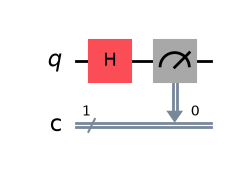

In [12]:
qc.draw('mpl')

In [13]:
simulator = Aer.get_backend('aer_simulator')

In [14]:
job = simulator.run(qc, shots=1000)
result = job.result()

In [15]:
# Get the measurement results
counts = result.get_counts(qc)
print(counts)

{'0': 514, '1': 486}


In [16]:
qc = QuantumCircuit(2) # Two-qubit Circuit

In [17]:
# Apply Hadamard gate to create superposition
qc.h(0)

In [18]:
# Applying a CNOT Gate
qc.cx(0, 1)

In [19]:
qc.measure_all()

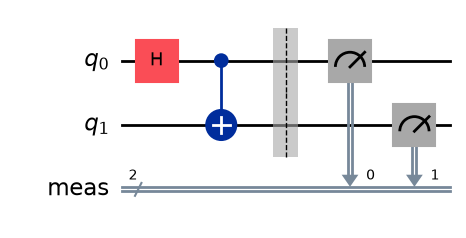

In [20]:
# Draw the circuit
qc.draw('mpl')

In [21]:
job = simulator.run(qc, shots=1000)
result = job.result()

In [22]:
# Get the measurement results
counts = result.get_counts(qc)
print(counts)

{'00': 514, '11': 486}


In [23]:
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import Aer

In [24]:
# Define the Oracle (marks the |11⟩ state)
def grover_oracle():
    oracle = QuantumCircuit(2)
    oracle.cz(0, 1)  # Controlled-Z gate to mark |11⟩
    return oracle

In [25]:
# Define the Diffusion Operator (amplifies the correct state)
def diffusion_operator():
    diffusion = QuantumCircuit(2)
    diffusion.h([0, 1])    # Apply Hadamard gates
    diffusion.x([0, 1])    # Apply X gates
    diffusion.cz(0, 1)     # Apply Controlled-Z gate
    diffusion.x([0, 1])    # Apply X gates again
    diffusion.h([0, 1])    # Apply Hadamard gates again
    return diffusion

In [26]:
qc = QuantumCircuit(2, 2)

In [27]:
qc.h([0, 1])

In [28]:
qc = qc.compose(grover_oracle())

In [29]:
qc = qc.compose(diffusion_operator())

In [30]:
qc.measure([0, 1], [0, 1])

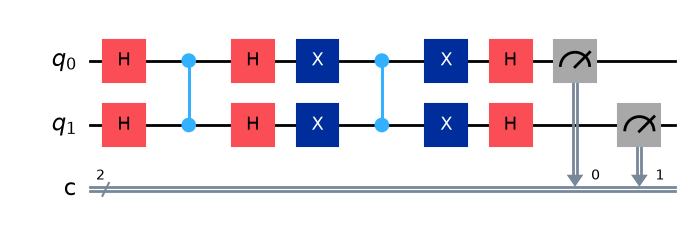

In [31]:
qc.draw('mpl')

In [32]:
simulator = Aer.get_backend('aer_simulator')

In [33]:
job = simulator.run(qc, shots=1000)
result = job.result()

In [34]:
counts = result.get_counts(qc)
print(counts)

{'11': 1000}


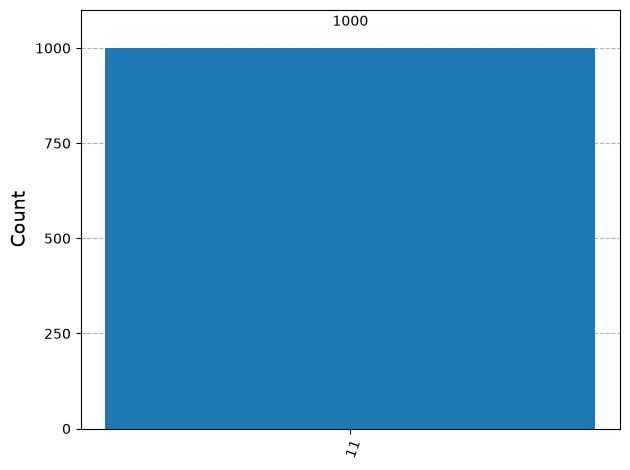

In [35]:
plot_histogram(counts) 